# Econ 4850 · Economic Analysis with Python
## Lecture 7a: Simulation
Geoffrey Kam, Washington University in St. Louis · g.kam@wustl.edu · Spring 2025

**What you'll learn**

- How to simulate any random variable from uniform draws using its quantile (inverse CDF) function.
- How Monte Carlo simulation approximates integrals and expectations, and why it relies on the law of large numbers and the central limit theorem.
- How to price European and barrier call options by Monte Carlo, first with loops and then with vectorized NumPy code.

We have already done some simulation in this course. Although there are packages that handle it well, it is worth learning how simulation works from first principles.

That first principle is related to a statement you will often see in econometrics papers: it is without loss of generality (WLOG) to assume that an error term follows a uniform distribution.

## Simulation from a Quantile Function

### Digression: The Cumulative Distribution Function (CDF)

The **cumulative distribution function (CDF)** of a random variable $X$ gives the probability that $X$ takes a value **less than or equal to** $x$:

$$
F(x) = P(X \leq x)
$$

where:
- $F(x)$ is the probability that $X$ is at most $x$;
- $X$ can be discrete or continuous;
- the CDF is a **non-decreasing function** that takes values between **0 and 1**.

#### Example 1: CDF of a Discrete Random Variable

Let $X$ be the outcome of rolling a fair six-sided die. Its probability mass function (PMF) is

$$
P(X = k) = \frac{1}{6}, \quad k = 1, 2, 3, 4, 5, 6.
$$

The CDF is obtained by summing these probabilities:

$$
F(x) =
\begin{cases}
0, & x < 1 \\
\frac{1}{6}, & 1 \leq x < 2 \\
\frac{2}{6}, & 2 \leq x < 3 \\
\frac{3}{6}, & 3 \leq x < 4 \\
\frac{4}{6}, & 4 \leq x < 5 \\
\frac{5}{6}, & 5 \leq x < 6 \\
1, & x \geq 6
\end{cases}
$$

#### Example 2: CDF of a Continuous Random Variable

A **Uniform(0, 1)** random variable has probability density function (PDF)

$$
f(x) =
\begin{cases}
1, & 0 \leq x \leq 1 \\
0, & \text{otherwise}
\end{cases}
$$

The CDF is obtained by integrating $f(x)$:

$$
F(x) =
\begin{cases}
0, & x < 0 \\
x, & 0 \leq x \leq 1 \\
1, & x > 1
\end{cases}
$$

### The Quantile Function

The quantile function, also called the inverse cumulative distribution function (inverse CDF), is a fundamental tool in simulation. Given a distribution with CDF $F(x)$, its quantile function is

$$
Q(p) = F^{-1}(p),
$$

where $p$ is a probability between 0 and 1. When $F$ is continuous and strictly increasing, $Q(p)$ is the value $x$ such that the probability of the random variable being less than or equal to $x$ is exactly $p$.

This is why we can simulate any random variable whose quantile function we can compute: draw an array of "random numbers" $U$ uniformly from $[0, 1]$ and transform them into $X = F^{-1}(U)$. The draws $X$ then have CDF $F$, because $P(F^{-1}(U) \leq x) = P(U \leq F(x)) = F(x)$.

#### Question

- What is the CDF of a Uniform(0, 1) random variable?
- What is the inverse of that CDF?

### When Does the Inverse of the CDF Exist?

The inverse of the CDF exists under certain conditions. For a random variable $X$ with CDF $F(x)$, the (generalized) inverse CDF is defined as

$$
F^{-1}(p) = \inf \{ x \in \mathbb{R} : F(x) \geq p \}, \quad \text{for } p \in (0,1).
$$

That is, $F^{-1}(p)$ is the smallest $x$ such that $P(X \leq x) \geq p$.

Roughly speaking:
1. If $F(x)$ is **strictly increasing**, the inverse is **unique**.
2. If $F(x)$ has **flat regions** or **jumps** (as in the discrete example above), the inverse is defined as the smallest $x$ such that $F(x) \geq p$.
3. The inverse **may not have a closed form**, but numerical methods (e.g., interpolation) can approximate it.

#### Exercise

You are given a CDF represented by two arrays, `x` and `y`.

**Write a function** that computes the inverse of this CDF: given a probability `p`, it should return the value `x` such that $F(x) = p$.

Hint: use [`np.interp`](https://numpy.org/doc/2.2/reference/generated/numpy.interp.html).

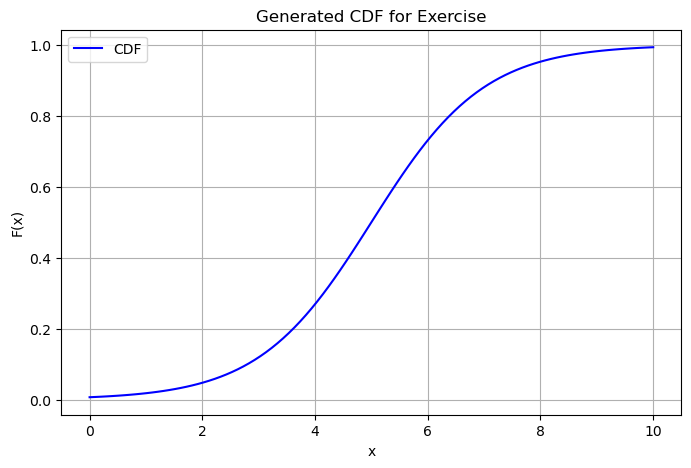

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# x values (the domain of the CDF)
x = np.linspace(0, 10, 100)

# Example CDF: a logistic CDF centred at x = 5
y = 1 / (1 + np.exp(-(x - 5)))

plt.figure(figsize=(8, 5))
plt.plot(x, y, label="CDF", color="blue")
plt.xlabel("x")
plt.ylabel("F(x)")
plt.title("Generated CDF for Exercise")
plt.grid()
plt.legend()
plt.show()

In [2]:
def inverse_cdf(p, x, y):
    # Interpolate in the inverse direction: from probabilities (y) back to values (x)
    return np.interp(p, y, x)

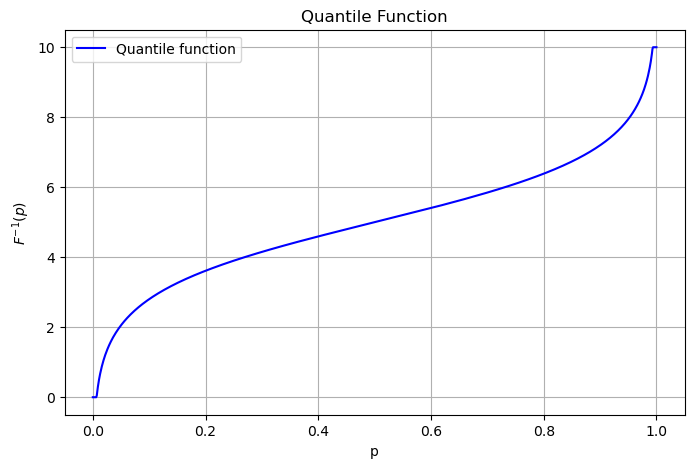

In [3]:
p_grid = np.linspace(0, 1, 1000)
inverse_cdf_values = inverse_cdf(p_grid, x, y)

plt.figure(figsize=(8, 5))
plt.plot(p_grid, inverse_cdf_values, label="Quantile function", color="blue")
plt.xlabel("p")
plt.ylabel(r"$F^{-1}(p)$")
plt.title("Quantile Function")
plt.grid()
plt.legend()
plt.show()

With this tool we can simulate any "well-behaved" random variable, such as stock prices, household earnings or household wealth.

We can then compute the expected value of functions of those variables, for example the expected utility of a hand-to-mouth household that lives off its income.

(Simulation also allows econometricians to infer information about unobservables, but the details are beyond the scope of this course.)

## An Introduction to Monte Carlo

Part of this lecture is adapted from [QuantEcon](https://intro.quantecon.org/monte_carlo.html#).

### What Is Monte Carlo Simulation?

Monte Carlo simulation involves:
1. generating random samples from a probability distribution;
2. performing numerical experiments on these samples;
3. using statistical properties of the results (e.g., mean, variance) to approximate the true value of a function, an expectation or a probability.

### Why Is Monte Carlo Important?

Monte Carlo is **extremely important** because it allows us to solve problems that are:

- **mathematically intractable**: many real-world models have no closed-form solution;
- **high-dimensional**: traditional numerical methods break down in higher dimensions;
- **complex and uncertain**: when uncertainty plays a role (e.g., in risk analysis), Monte Carlo provides probabilistic insights.

### Example: Approximating an Integral

Suppose we want to compute

$$
I = \int_0^1 e^x \, dx = e - 1.
$$

Instead of solving it analytically, we can **approximate it by Monte Carlo**:

1. Generate **random numbers** $x_1, x_2, \dots, x_N$ uniformly from $[0, 1]$.
2. Evaluate the function $e^x$ at these points.
3. Take the average:

$$
I \approx \frac{1}{N} \sum_{i=1}^{N} e^{x_i}.
$$

As $N \to \infty$, the estimate **converges** to the true value, provided the regularity conditions of the law of large numbers hold (see below).

#### Exercise

Approximate $I$ using Monte Carlo.

In [4]:
def monte_carlo_integral(N):
    """
    Approximate the integral I = ∫_0^1 e^x dx using Monte Carlo.

    Parameters:
        N (int): Number of random samples.

    Returns:
        float: Monte Carlo estimate of the integral.
    """
    # Step 1: generate N uniform random numbers in [0, 1]
    x_samples = np.random.uniform(0, 1, N)

    # Step 2: evaluate e^x at each draw
    fx_values = np.exp(x_samples)

    # Step 3: the Monte Carlo estimate is the sample mean
    estimate = np.mean(fx_values)

    return estimate


# Compare with the exact value for different sample sizes
N_values = [100, 1000, 10000, 1000000]
true_value = np.exp(1) - 1
print(f"True value of the integral: {true_value:.10f}")
for N in N_values:
    estimate = monte_carlo_integral(N)
    error = abs(estimate - true_value)
    print(f"N = {N}, Monte Carlo Estimate = {estimate:.6f}, Error = {error:.6f}")

True value of the integral: 1.7182818285
N = 100, Monte Carlo Estimate = 1.747264, Error = 0.028982
N = 1000, Monte Carlo Estimate = 1.720497, Error = 0.002215
N = 10000, Monte Carlo Estimate = 1.724073, Error = 0.005791
N = 1000000, Monte Carlo Estimate = 1.718948, Error = 0.000666


For comparison, SciPy's numerical integration routine `quad` returns the integral together with an estimate of its numerical error:

In [5]:
import scipy.integrate as integrate

integral, quad_error = integrate.quad(lambda x: np.exp(x), 0, 1)
print(integral, quad_error)

1.7182818284590453 1.9076760487502457e-14


### Caveat: The Law of Large Numbers and the Central Limit Theorem in Monte Carlo Methods

Monte Carlo methods rely on **random sampling** to approximate numerical values. They are often used for **integration, optimization and statistical estimation**. The **law of large numbers (LLN)** and the **central limit theorem (CLT)** are what make Monte Carlo estimates accurate and reliable.

#### 1. The Law of Large Numbers and Monte Carlo

Monte Carlo estimation typically involves computing the **sample mean** of some function $g(X)$, where $X$ follows a given probability distribution. The Monte Carlo estimate of the expectation $\mathbb{E}[g(X)]$ is

$$
\hat{\mu}_n = \frac{1}{n} \sum_{i=1}^{n} g(X_i)
$$

where:
- $X_1, X_2, \dots, X_n$ are **i.i.d.** random variables;
- $g(X)$ is the function of interest;
- $\hat{\mu}_n$ is the **Monte Carlo estimate** of $\mathbb{E}[g(X)]$.

The **law of large numbers** states that, as the sample size $n$ increases,

$$
\hat{\mu}_n \to \mathbb{E}[g(X)] \quad \text{almost surely}.
$$

So for a sufficiently large $n$, the sample mean is close to the true expected value with high probability.

#### 2. The Central Limit Theorem and Monte Carlo

The **central limit theorem** quantifies the uncertainty in Monte Carlo estimates. If $g(X)$ has **finite variance** $\sigma^2$, then for large $n$ the sample mean satisfies

$$
\sqrt{n} \left( \hat{\mu}_n - \mathbb{E}[g(X)] \right) \approx \mathcal{N}(0, \sigma^2).
$$

Rearranging,

$$
\hat{\mu}_n \approx \mathbb{E}[g(X)] + \mathcal{N} \left( 0, \frac{\sigma^2}{n} \right).
$$

That is, for large $n$ the sample mean is approximately normally distributed, with a variance that shrinks as $n$ grows.

#### 3. When the LLN and CLT Fail

The LLN requires $\mathbb{E}[g(X)]$ to be **finite**, and the CLT additionally requires the **variance** of $g(X)$ to be finite. If $g(X)$ follows a heavy-tailed distribution (e.g., the Cauchy distribution), then:

- the **LLN may fail**: the sample mean need not converge to a finite expected value;
- the **CLT may fail**: the normal approximation for the sample mean is invalid.

In such cases, Monte Carlo methods become unreliable unless alternative techniques (e.g., importance sampling) are used.

#### 4. Practical Implications for Monte Carlo Simulation

- **A large $n$ is required.** The accuracy of Monte Carlo estimates improves with more samples, but convergence is **slow**: to **reduce the error by a factor of 10, we need 100 times more samples**.
- **Variance reduction matters.** Because Monte Carlo converges at rate $O(1/\sqrt{n})$, methods such as **importance sampling, stratified sampling and control variates** can improve efficiency.
- **Heavy-tailed distributions need special treatment.** If the underlying distribution has no finite mean or variance, standard Monte Carlo methods may fail.

Let's illustrate this by comparing Monte Carlo estimates of the mean of a normal distribution with those of a Cauchy distribution.

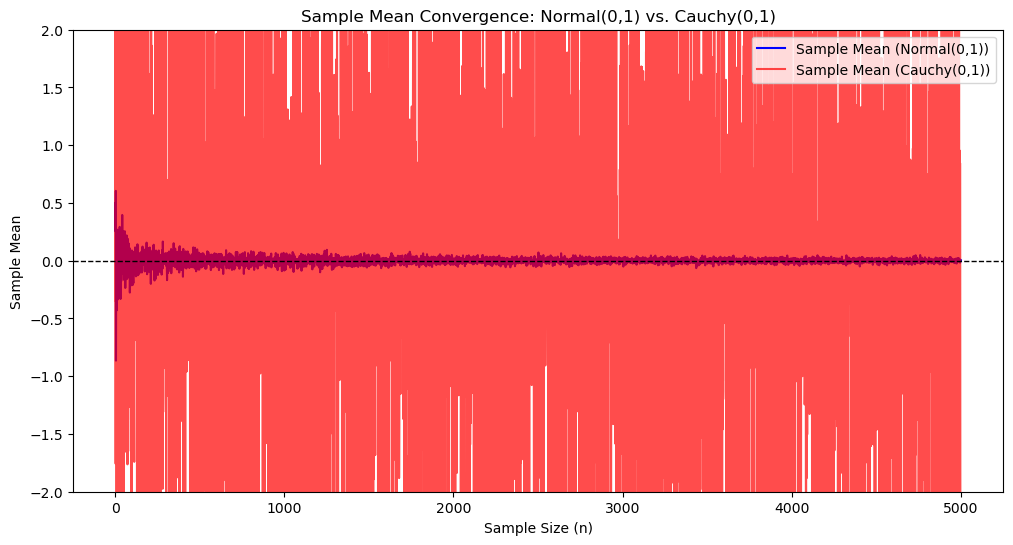

In [6]:
# Set random seed for reproducibility
np.random.seed(42)

# Sample sizes to consider
sample_sizes = np.arange(1, 5001)

# Sample mean of n draws, for each sample size n
normal_means = np.array([np.mean(np.random.normal(0, 1, size=n)) for n in sample_sizes])
cauchy_means = np.array([np.mean(np.random.standard_cauchy(size=n)) for n in sample_sizes])

plt.figure(figsize=(12, 6))
plt.plot(sample_sizes, normal_means, label="Sample Mean (Normal(0,1))", color="blue")
plt.plot(sample_sizes, cauchy_means, label="Sample Mean (Cauchy(0,1))", color="red", alpha=0.7)

# Reference line at the normal mean (the Cauchy distribution has no mean)
plt.axhline(y=0, color="black", linestyle="--", linewidth=1)

plt.xlabel("Sample Size (n)")
plt.ylabel("Sample Mean")
plt.title("Sample Mean Convergence: Normal(0,1) vs. Cauchy(0,1)")
plt.ylim(-2, 2)
plt.legend()
plt.show()

## Option Pricing

This part follows [QuantEcon](https://intro.quantecon.org/monte_carlo.html).

### European Call Option

A **European call option** gives the holder the right to buy an asset at a predetermined strike price $K$ at maturity $T$.

For simplicity, we assume risk-neutral pricing: the option price is the present value of its expected payoff under the risk-neutral measure,

$$
C = e^{-rT} \mathbb{E}[(S_T - K)^+]
$$

where:
- $S_T$ is the stock price at maturity;
- $r$ is the risk-free rate;
- $(x)^+$ denotes $\max(x, 0)$, so payoffs are non-negative.

Monte Carlo simulation estimates this expectation by generating many simulated price paths for $S_T$ and averaging the discounted payoffs.

In the code below, time is measured in $n$ discrete periods and we discount with a per-period discount factor $\beta$ (playing the role of $e^{-r}$), so the discount term $e^{-rT}$ becomes $\beta^n$.

### Modeling Stock Prices

Assume $\{S_t\}$ follows

$$
\ln\frac{S_{t+1}}{S_t} = \mu + \sigma_t \xi_{t+1}
$$

where

$$
\sigma_t = \exp(h_t), \quad h_{t+1} = \rho h_t + \nu \eta_{t+1},
$$

- $S_0$ and $h_0$ are given;
- $\{\xi_t\}$ and $\{\eta_t\}$ are IID standard normal and independent of each other.

Because volatility $\sigma_t$ is itself random, $S_t$ is lognormal only conditional on the volatility path, and there is no simple closed-form option price. This is where Monte Carlo helps. With these parameters $S_T$ has a heavy right tail, so estimates from $M = 10{,}000$ draws are noisy and vary noticeably from run to run; increasing $M$ is the remedy.

Strictly, risk-neutral pricing also requires the stock to earn the risk-free rate in expectation, $\mathbb{E}[S_{t+1}/S_t] = 1/\beta$. The parameters below (taken from QuantEcon) do not impose this: with $\sigma_t \approx 1$, $\mathbb{E}[S_{t+1}/S_t] \approx e^{0.5} \approx 1.65$, against $1/\beta \approx 1.05$. Treat the resulting numbers as an illustration of the Monte Carlo method rather than as arbitrage-free prices.

In [7]:
from collections import namedtuple
from numpy.random import randn

# A named tuple bundles the model parameters
Parameters = namedtuple("Parameters", ["mu", "rho", "nu", "S0", "h0", "K", "n", "beta"])

params = Parameters(
    mu=0.0001,
    rho=0.1,
    nu=0.001,
    S0=10,
    h0=0,
    K=100,
    n=10,
    beta=0.95
)

# Fields are accessed by name
print(params.mu)   # Output: 0.0001
print(params)      # Display all parameters

0.0001
Parameters(mu=0.0001, rho=0.1, nu=0.001, S0=10, h0=0, K=100, n=10, beta=0.95)


In [8]:
def simulate_asset_price_path(params):
    """Simulate one path S_0, ..., S_n of the stock price."""
    s = np.empty(params.n + 1)  # log price
    s[0] = np.log(params.S0)

    h = params.h0
    for t in range(params.n):
        s[t + 1] = s[t] + params.mu + np.exp(h) * randn()
        h = params.rho * h + params.nu * randn()

    return np.exp(s)

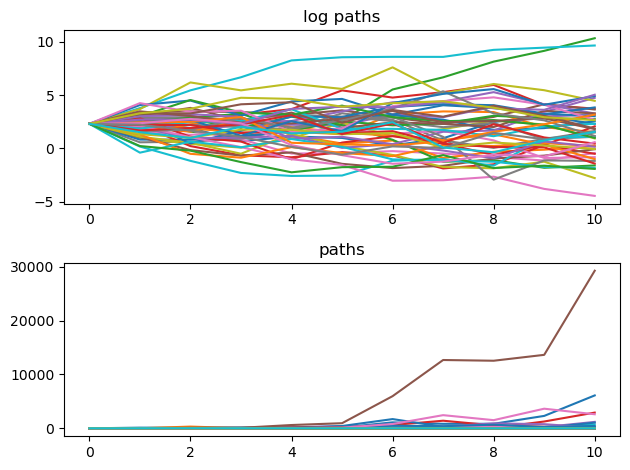

In [9]:
fig, axes = plt.subplots(2, 1)
titles = "log paths", "paths"
transforms = np.log, lambda path: path

for ax, transform, title in zip(axes, transforms, titles):
    for _ in range(50):
        path = simulate_asset_price_path(params)
        ax.plot(transform(path))
    ax.set_title(title)

fig.tight_layout()
plt.show()

In [10]:
def compute_call_price(params, M=10_000):
    """Monte Carlo price of a European call, looping over M sample paths."""
    current_sum = 0.0
    for _ in range(M):
        s = np.log(params.S0)
        h = params.h0
        # Simulate forward in time
        for t in range(params.n):
            s = s + params.mu + np.exp(h) * randn()
            h = params.rho * h + params.nu * randn()
        # Add this path's option payoff
        current_sum += np.maximum(np.exp(s) - params.K, 0)

    return params.beta**params.n * current_sum / M


call_price = compute_call_price(params)
print(call_price)

597.7753891311487


In [11]:
%%timeit
compute_call_price(params)

106 ms ± 849 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


#### Exercise 1

Vectorize the function above. In other words, do not use a `for` loop over the $M$ sample paths.

In [12]:
def compute_call_price_vector(params, M=10_000):
    """Monte Carlo price of a European call, simulating all M paths at once."""
    s = np.full(M, np.log(params.S0))
    h = np.full(M, params.h0)

    for t in range(params.n):
        Z = np.random.randn(2, M)
        s = s + params.mu + np.exp(h) * Z[0, :]
        h = params.rho * h + params.nu * Z[1, :]

    expectation = np.mean(np.maximum(np.exp(s) - params.K, 0))
    return params.beta**params.n * expectation


call_price_vector = compute_call_price_vector(params)
print(call_price_vector)

699.5198454971081


In [13]:
%%timeit
compute_call_price_vector(params)

3.88 ms ± 27.1 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


#### Exercise 2

Consider a European call option with strike \$100 written on the underlying above (spot price \$10, i.e. $S_0 = 10$, with the same parameters as before) and a knockout barrier of \$150.

This option behaves in every way like a vanilla European call, except that if the spot price ever moves above \$150 (checked at the end of each of the $n$ periods), the option "knocks out" and the contract is null and void. The option does not reactivate if the spot price later falls below \$150 again.

Do not use a `for` loop over $M$.

Hint: use `np.where`.

The solution below stores the barrier price as `bp = 150`; try other values yourself.

In [14]:
# Add the barrier price (bp) to the parameters
BarrierParameters = namedtuple(
    "BarrierParameters", ["mu", "rho", "nu", "S0", "h0", "K", "n", "beta", "bp"]
)

barrier_params = BarrierParameters(
    mu=0.0001,
    rho=0.1,
    nu=0.001,
    S0=10,
    h0=0,
    K=100,
    n=10,
    beta=0.95,
    bp=150  # example barrier price
)


def compute_call_price_with_barrier_vector(params, M=50_000):
    """Monte Carlo price of a knock-out barrier call, simulating all M paths at once."""
    s = np.full(M, np.log(params.S0))
    h = np.full(M, params.h0)
    option_is_null = np.full(M, False)

    for t in range(params.n):
        Z = np.random.randn(2, M)
        s = s + params.mu + np.exp(h) * Z[0, :]
        h = params.rho * h + params.nu * Z[1, :]
        # Knock out every path whose price has crossed the barrier
        option_is_null = np.where(np.exp(s) > params.bp, True, option_is_null)

    # Knocked-out options pay nothing
    payoff = np.where(option_is_null, 0, np.maximum(np.exp(s) - params.K, 0))
    expectation = np.mean(payoff)

    return params.beta**params.n * expectation


call_price_with_barrier_vector = compute_call_price_with_barrier_vector(barrier_params)
print(call_price_with_barrier_vector)

0.23139457298347926
